<a href="https://colab.research.google.com/github/slavyolov/Algorithms/blob/main/RFMT_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install faker -q

## Raw Data

In [2]:
from faker import Faker
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

fake = Faker()

# Specify the number of dataset rows and customers
num_rows = 1000
num_customers = 300

# Simulate repeat customers
customer_ids = np.random.choice(np.arange(100, 10000), num_customers, replace=False)
repeat_ids = np.random.choice(customer_ids, num_rows)

# Random purchase dates over past 2 years
purchase_dates = [fake.date_between(start_date='-2y', end_date='today') for _ in range(num_rows)]

# Amounts between 10 and 1000
transaction_amounts = np.round(np.random.uniform(10, 1000, num_rows), 2)

# 4 possible products
product_info = np.random.choice(['Tasty Bites', 'T-Shirt Mouse', 'Penguin Snack', 'Handy Thing'], num_rows)

# 6-digit unique order ids
order_ids = np.random.randint(100000, 999999, num_rows)

# Use Faker for locations
locations = [fake.city() for _ in range(num_rows)]

df = pd.DataFrame({
    'customer_id': repeat_ids,
    'purchase_date': purchase_dates,
    'transaction_amount': transaction_amounts,
    'product_information': product_info,
    'order_id': order_ids,
    'location': locations
})

df.head()


,customer_id,purchase_date,transaction_amount,product_information,order_id,location
0,9920,2026-08-08,708.01,T-Shirt Mouse,384331,Thomaston
1,632,2025-05-17,456.48,Handy Thing,753009,North Markchester
2,1962,2025-10-31,109.75,Handy Thing,730971,East Roger
3,6519,2025-03-20,710.45,Tasty Bites,887646,West Jeremy
4,1324,2026-07-16,40.86,Penguin Snack,910372,Banksmouth


# RFM

## Recency

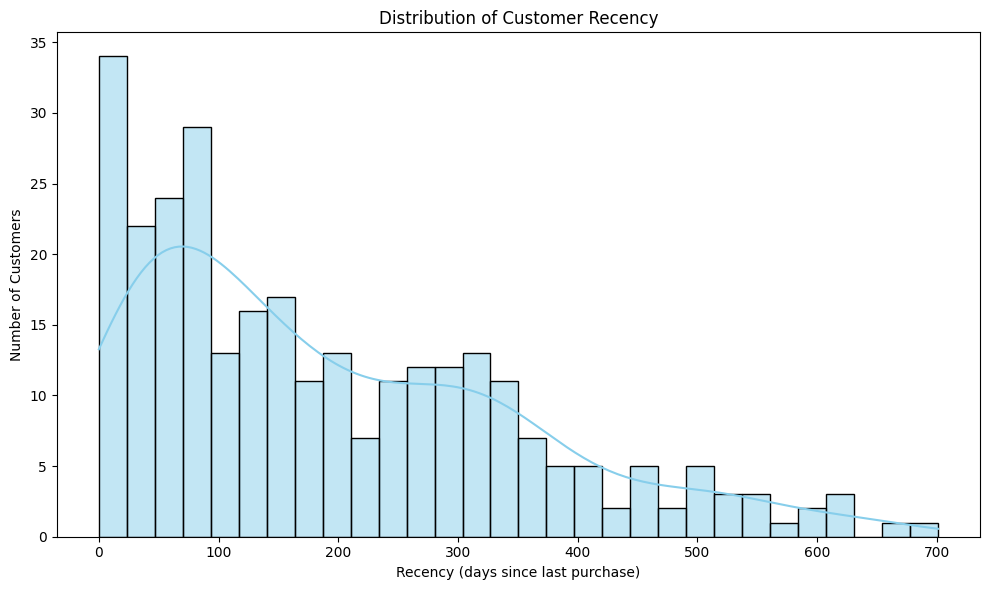

In [3]:

# Ensure date column is interpreted as datetime
df['purchase_date'] = pd.to_datetime(df['purchase_date'])

# Compute each customer's most recent purchase
df_recency = df.groupby(by='customer_id', as_index=False)['purchase_date'].max()
df_recency.columns = ['customer_id', 'last_purchase_date']

# Find most recent date in dataset for recency calculation
recent_date = df_recency['last_purchase_date'].max()

# Calculate recency in days (how long since last purchase)
df_recency['recency'] = df_recency['last_purchase_date'].apply(lambda x: (recent_date - x).days)

# Visualize distribution of recency using seaborn
plt.figure(figsize=(10, 6))
sns.histplot(df_recency['recency'], bins=30, kde=True, color="skyblue")
plt.title('Distribution of Customer Recency')
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


## Frequency

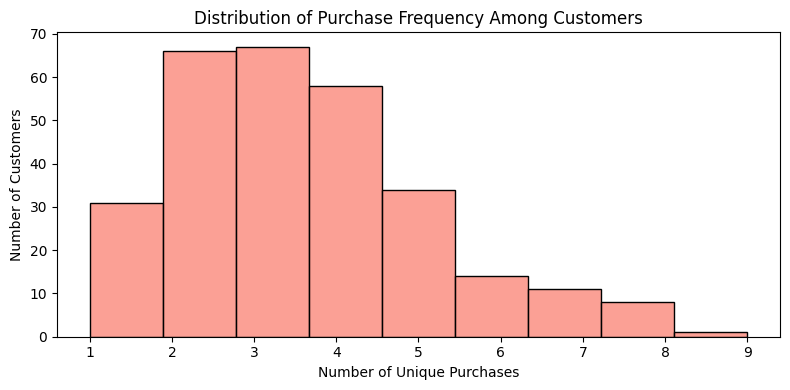

In [4]:
# Remove duplicate purchase records to count only unique transactions
frequency_df = df.drop_duplicates().groupby(by=['customer_id'], as_index=False)['purchase_date'].count()

# Rename columns for clarity
frequency_df.columns = ['customer_id', 'frequency']

# Display first few rows
frequency_df.head()

# Visualization: Distribution of purchase frequency
plt.figure(figsize=(8, 4))
sns.histplot(frequency_df['frequency'], bins=9, kde=False, color="salmon")
plt.title('Distribution of Purchase Frequency Among Customers')
plt.xlabel('Number of Unique Purchases')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


## Monetary Value

In [5]:
# Create a new column 'total' to store transaction amounts for each purchase
df['total'] = df['transaction_amount']

# Group data by customer_id and sum the total transaction amounts per customer
monetary_df = df.groupby(by='customer_id', as_index=False)['total'].sum()

# Rename the columns to lowercase and meaningful names
monetary_df.columns = ['customer_id', 'monetary']

# Display the first few rows
monetary_df.head()


,customer_id,monetary
0,129,1670.10
1,131,3217.51
2,133,3632.25
3,139,351.06
4,188,1926.96


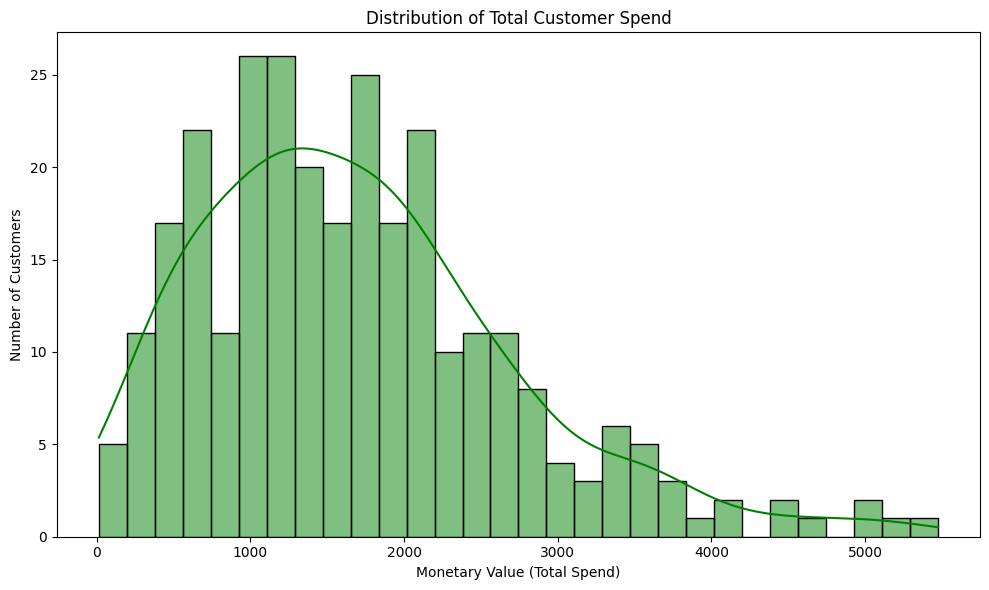

In [6]:
plt.figure(figsize=(10, 6))
sns.histplot(monetary_df['monetary'], bins=30, kde=True, color='green')
plt.title('Distribution of Total Customer Spend')
plt.xlabel('Monetary Value (Total Spend)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


## RFM Score

In [7]:
# Merge recency and frequency dataframes on customer_id to combine their metrics
rf_df = df_recency.merge(frequency_df, on='customer_id')

# Merge the above result with monetary dataframe and drop the redundant last_purchase_date column
rfm_df = rf_df.merge(monetary_df, on='customer_id').drop(columns='last_purchase_date')

# Assign ranks to customers: lower recency (more recent) ranks higher (descending),
# while higher frequency and monetary values rank higher (ascending)
rfm_df['R_rank'] = rfm_df['recency'].rank(ascending=False)
rfm_df['F_rank'] = rfm_df['frequency'].rank(ascending=True)
rfm_df['M_rank'] = rfm_df['monetary'].rank(ascending=True)

# Normalize ranks to a 0-100 scale for comparability across the metrics
rfm_df['R_rank_norm'] = (rfm_df['R_rank'] / rfm_df['R_rank'].max()) * 100
rfm_df['F_rank_norm'] = (rfm_df['F_rank'] / rfm_df['F_rank'].max()) * 100
rfm_df['M_rank_norm'] = (rfm_df['M_rank'] / rfm_df['M_rank'].max()) * 100

# After normalization, drop the intermediate rank columns as they are no longer needed
rfm_df.drop(columns=['R_rank', 'F_rank', 'M_rank'], inplace=True)

# Show the first few rows of the final dataframe
rfm_df.head()


,customer_id,recency,frequency,monetary,R_rank_norm,F_rank_norm,M_rank_norm
0,129,95,4,1670.10,61.871750,66.724138,54.137931
1,131,23,8,3217.51,89.254766,98.448276,91.724138
2,133,22,6,3632.25,89.948007,90.862069,95.517241
3,139,266,1,351.06,31.542461,5.517241,4.827586
4,188,174,4,1926.96,45.060659,66.724138,64.482759


In [8]:
# Define weights for each RFM component based on business priorities
weight_recency = 0.15
weight_frequency = 0.3
weight_monetary = 0.55

# Calculate the composite RFM score as a weighted sum of normalized ranks
rfm_df['RFM_Score'] = \
    weight_recency * rfm_df['R_rank_norm'] + \
    weight_frequency * rfm_df['F_rank_norm'] + \
    weight_monetary * rfm_df['M_rank_norm']

# Scale down the RFM score for easier interpretation or alignment with business KPIs
rfm_df['RFM_Score'] *= 0.05
rfm_df = rfm_df.round(2)

rfm_df.head()

,customer_id,recency,frequency,monetary,R_rank_norm,F_rank_norm,M_rank_norm,RFM_Score
0,129,95,4,1670.10,61.87,66.72,54.14,2.95
1,131,23,8,3217.51,89.25,98.45,91.72,4.67
2,133,22,6,3632.25,89.95,90.86,95.52,4.66
3,139,266,1,351.06,31.54,5.52,4.83,0.45
4,188,174,4,1926.96,45.06,66.72,64.48,3.11


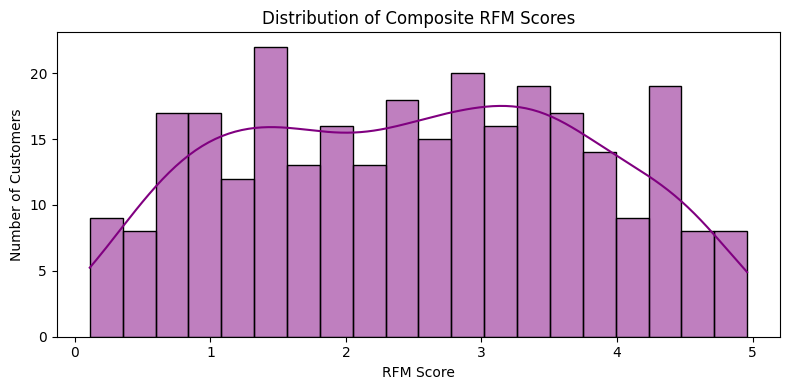

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
sns.histplot(rfm_df['RFM_Score'], bins=20, kde=True, color='purple')
plt.title('Distribution of Composite RFM Scores')
plt.xlabel('RFM Score')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


## Segment Customers

In [10]:
import numpy as np

# Define thresholds at 20th, 50th, and 80th percentiles of the RFM score
percentiles = np.percentile(rfm_df['RFM_Score'], [20, 50, 80])

# Apply conditions based on percentile thresholds
rfm_df['Customer_Segment'] = np.where(rfm_df['RFM_Score'] >= percentiles[2], 'Top Customers',
                             np.where(rfm_df['RFM_Score'] >= percentiles[1], 'High Value Customers',
                             np.where(rfm_df['RFM_Score'] >= percentiles[0], 'Medium Value Customers', 'Low Value Customers')))

# Display segment distribution
print(rfm_df['Customer_Segment'].value_counts())


Customer_Segment
High Value Customers      87
Medium Value Customers    87
Top Customers             58
Low Value Customers       58
Name: count, dtype: int64


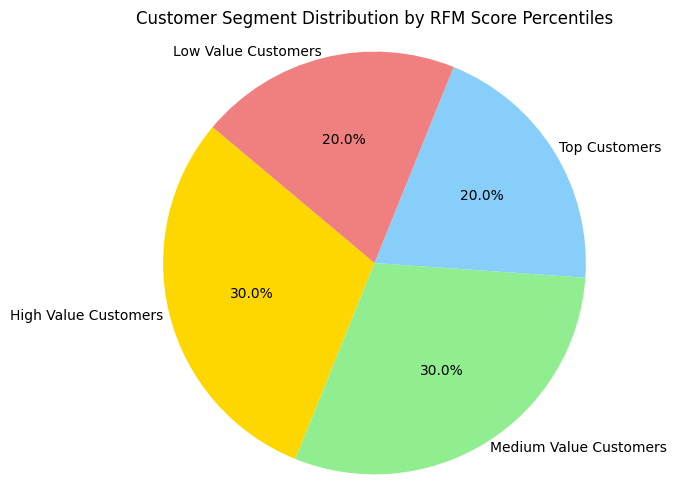

In [11]:
import matplotlib.pyplot as plt

# Count the occurrences of each segment
segment_counts = rfm_df['Customer_Segment'].value_counts()

# Create a pie chart
plt.figure(figsize=(6, 6))
plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%',
        startangle=140, colors=['gold', 'lightgreen', 'lightskyblue', 'lightcoral'],
        labeldistance=1.03)
plt.title("Customer Segment Distribution by RFM Score Percentiles")
plt.axis('equal')  # Equal aspect ratio ensures the pie chart is circular
plt.show()


# RFMT

## Tenure
- First, we identify each customer's earliest recorded transaction.
- We then calculate the number of days between that date and the analysis date.

In [12]:

# Use the same analysis date as the original RFM calculation
analysis_date = pd.to_datetime(recent_date)

# Find each customer's first recorded purchase
df_tenure = (
    df.groupby('customer_id', as_index=False)['purchase_date']
      .min()
)

# Rename the date column
df_tenure.columns = ['customer_id', 'first_purchase_date']

# Calculate customer tenure in days
df_tenure['tenure_days'] = (
    analysis_date - df_tenure['first_purchase_date']
).dt.days

# Convert days into approximate months
df_tenure['tenure_months'] = (
    df_tenure['tenure_days'] / 30.4375
)

df_tenure.head()

,customer_id,first_purchase_date,tenure_days,tenure_months
0,129,2025-07-26,460,15.112936
1,131,2024-11-09,719,23.622177
2,133,2025-02-04,632,20.763860
3,139,2026-02-05,266,8.739220
4,188,2025-05-22,525,17.248460


## Combine Tenure with Our Existing RFM Dataset

In [13]:
# Merge tenure information with the existing RFM dataframe
rfmt_df = rfm_df.merge(
    df_tenure,
    on='customer_id',
    how='left'
)

# Display the extended dataset
rfmt_df[
    ['customer_id', 'recency', 'frequency',
     'monetary', 'tenure_days', 'tenure_months']
].head()

,customer_id,recency,frequency,monetary,tenure_days,tenure_months
0,129,95,4,1670.10,460,15.112936
1,131,23,8,3217.51,719,23.622177
2,133,22,6,3632.25,632,20.763860
3,139,266,1,351.06,266,8.739220
4,188,174,4,1926.96,525,17.248460


## Visualize Customer Tenure

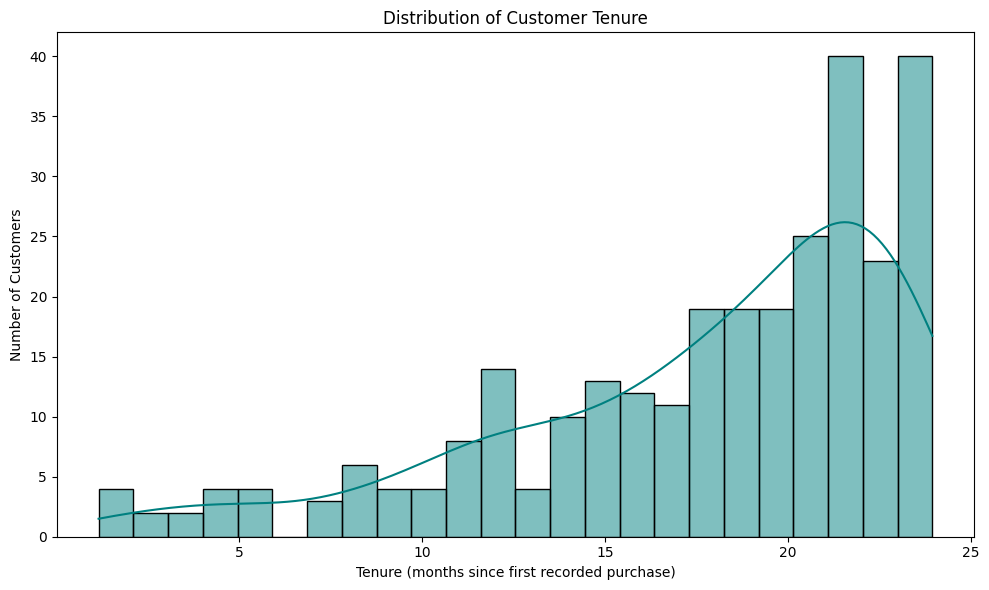

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    rfmt_df['tenure_months'],
    bins=24,
    kde=True,
    color='teal'
)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (months since first recorded purchase)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

## Create Tenure-Based Customer Groups

In [15]:
# Define tenure intervals in months
tenure_bins = [-0.001, 3, 6, 12, np.inf]

tenure_labels = [
    '0-3 Months',
    '3-6 Months',
    '6-12 Months',
    '12+ Months'
]

# Assign customers to tenure groups
rfmt_df['Tenure_Band'] = pd.cut(
    rfmt_df['tenure_months'],
    bins=tenure_bins,
    labels=tenure_labels,
    right=False
)

# Display the distribution
rfmt_df['Tenure_Band'].value_counts().sort_index().reset_index()

,Tenure_Band,count
0,0-3 Months,6
1,3-6 Months,10
2,6-12 Months,31
3,12+ Months,243


## Visualize RFM Scores Against Tenure

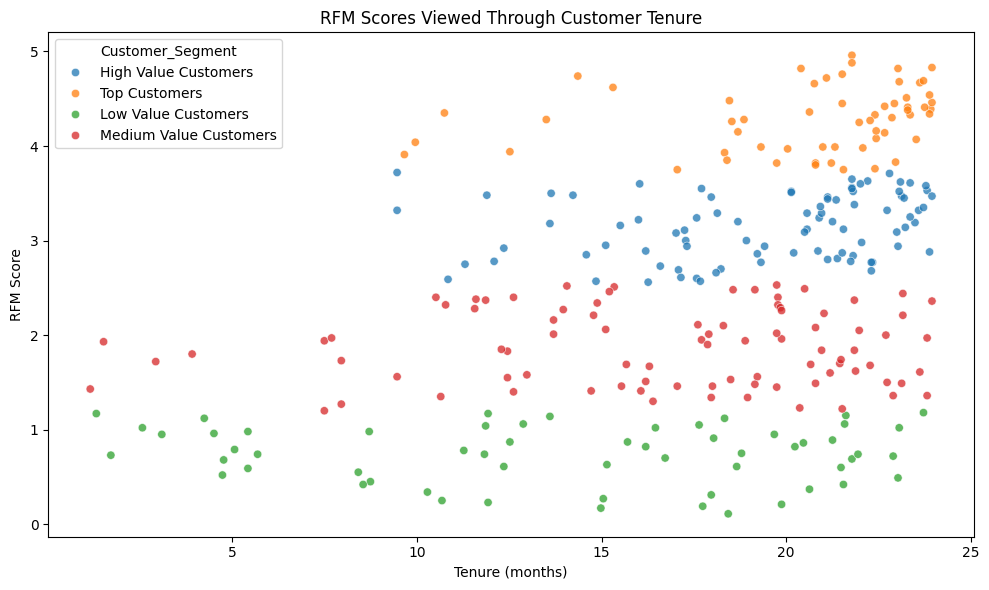

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfmt_df,
    x='tenure_months',
    y='RFM_Score',
    hue='Customer_Segment',
    alpha=0.75
)

plt.title('RFM Scores Viewed Through Customer Tenure')
plt.xlabel('Tenure (months)')
plt.ylabel('RFM Score')

plt.tight_layout()
plt.show()

## Split Existing RFM Segments by Tenure

In [17]:
# Create a cross-tabulation of RFM segments and tenure groups
tenure_split = pd.crosstab(
    rfmt_df['Customer_Segment'],
    rfmt_df['Tenure_Band']
).reset_index()

display(tenure_split)

Tenure_Band,Customer_Segment,0-3 Months,3-6 Months,6-12 Months,12+ Months
0,High Value Customers,0,0,5,82
1,Low Value Customers,3,9,11,35
2,Medium Value Customers,3,1,12,71
3,Top Customers,0,0,3,55


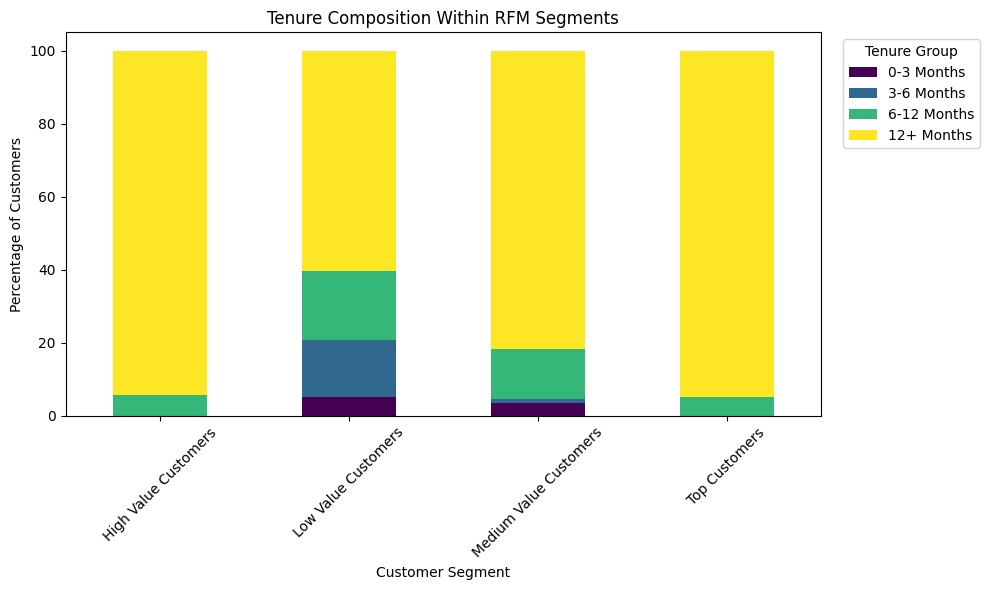

In [18]:
# We can also visualize the percentage distribution of tenure within each RFM segment.

# Calculate the percentage distribution within each RFM segment
tenure_split_pct = pd.crosstab(
    rfmt_df['Customer_Segment'],
    rfmt_df['Tenure_Band'],
    normalize='index'
) * 100

# Visualize the results
ax = tenure_split_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='viridis'
)

ax.set_title('Tenure Composition Within RFM Segments')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Percentage of Customers')

# Rotate the x-axis tick labels (the segment names) instead of the main axis label
plt.xticks(rotation=45)

ax.legend(
    title='Tenure Group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()